In [2]:
# Exercise 1 — check your environment: Python, the Week 10 and 11 packages, Ollama and two models.
# Ollama = the free app that runs the AI models on your own laptop. Each check prints one line:
# OK, or NOT OK followed by the fix to try. Result: the settings below plus a list of checks.
# PREPARED: just run it. No Ollama (or a slow laptop)? Set USE_RECORDED = True to replay the recorded real run.
import base64, hashlib, importlib, json, platform, re, sys, time   # standard-library helpers used in this notebook
from pathlib import Path                                  # file paths for Windows and macOS

# Settings used by the whole notebook. Replay mode = reuse the saved real replies of a finished run,
# so you do not need Ollama. Live mode = really ask the models on your laptop.
USE_RECORDED = False                       # True = replay mode: use the recorded real replies and vectors (no Ollama). False = live: ask Ollama.
# 127.0.0.1 means "this computer". We avoid "localhost": on Windows it adds about 2 s per request.
OLLAMA_URL = "http://127.0.0.1:11434"      # 127.0.0.1, not localhost: on Windows localhost adds ~2 s per request
MODEL = "qwen2.5:3b"                       # the chat model, as in Week 10 (qwen2.5:1.5b works, but replay will not match)
# An embedding = a list of numbers (a vector) that captures the meaning of a text.
EMBED_MODEL = "nomic-embed-text:latest"    # the embedding model: turns a text into 768 numbers
SEED = 11523                               # fixed seed: usually the same reply on the same machine (not guaranteed; see Step 0.5)

# Helper: print one line per check, so you can see at a glance what works and what to fix.
def check(name, ok, fix):                                 # print one OK / NOT OK line, with the fix if needed
    print(("OK      " if ok else "NOT OK  ") + name + ("" if ok else "   ->  FIX: " + fix))   # one line per check

# Check 1: which Python runs this notebook, and is it new enough?
print("Python", sys.version.split()[0], "on", platform.system())   # which Python runs this notebook
check("Python 3.9 or newer", sys.version_info >= (3, 9), "install Python 3.11 from python.org")   # minimum version
# Check 2: can each Week 10 package be imported (import = load a package so that we can use it)?
for pkg in ["pandas", "requests", "sklearn", "matplotlib", "pydantic"]:   # the Week 10 packages
    try:                                                  # try to import it
        importlib.import_module(pkg)                      # import the package from its name
        check("package " + pkg + " (Week 10)", True, "")  # it is installed
    except ImportError:                                   # the import failed: it is not installed
        check("package " + pkg + " (Week 10)", False, "do Week 10 Step 0 first, then restart the kernel")   # fix
# Check 3: the same test for the two new Week 11 packages.
for pkg in ["numpy", "chromadb"]:                         # the Week 11 packages (numpy comes with pandas)
    try:                                                  # try to import it
        importlib.import_module(pkg)                      # import the package from its name
        check("package " + pkg + " (Week 11)", True, "")  # it is installed
    except ImportError:                                   # the import failed: it is not installed
        check("package " + pkg + " (Week 11)", False, "pip install -r requirements_week11.txt, then restart the kernel")   # fix

# Check 4: is Ollama running, and are both models downloaded? (Skipped in replay mode.)
import requests                                           # HTTP library used to talk to Ollama
if USE_RECORDED:                                          # replay mode: Ollama is not needed
    print("SKIPPED (replay mode)  Ollama server, " + MODEL + ", " + EMBED_MODEL)   # nothing to check
else:                                                     # live mode: Ollama must be running
    try:                                                  # ask Ollama which models are downloaded
        # The /api/tags address lists the downloaded models; we keep only their names.
        names = [m["name"] for m in requests.get(OLLAMA_URL + "/api/tags", timeout=5).json()["models"]]   # model names
        server_ok = True                                  # the server answered
    except Exception:                                     # no answer: Ollama is not running
        names, server_ok = [], False                      # so no models are visible
    check("Ollama server at " + OLLAMA_URL, server_ok, "open the Ollama app (or `ollama serve`), or set USE_RECORDED = True")   # server
    check("model " + MODEL, MODEL in names, "ollama pull " + MODEL)                       # chat model downloaded?
    check("model " + EMBED_MODEL, EMBED_MODEL in names, "ollama pull nomic-embed-text")   # embedding model downloaded?
print("Mode:", "REPLAY recorded replies" if USE_RECORDED else "LIVE Ollama calls")       # which mode is on

Python 3.11.17 on Windows
OK      Python 3.9 or newer
OK      package pandas (Week 10)
OK      package requests (Week 10)
OK      package sklearn (Week 10)
OK      package matplotlib (Week 10)
OK      package pydantic (Week 10)
OK      package numpy (Week 11)
OK      package chromadb (Week 11)
OK      Ollama server at http://127.0.0.1:11434
OK      model qwen2.5:3b
OK      model nomic-embed-text:latest
Mode: LIVE Ollama calls


In [3]:
# PREPARED — the two Ollama helpers: post_to_ollama() for the chat model (as in Week 10) and
# embed_texts() for the embedding model. Both support replay: in replay mode they return the
# recorded real answer instead of calling Ollama. Every live reply is also saved in outputs/, so
# your own run can be replayed offline later. Result: two functions used by every later cell.
import numpy as np                                        # numpy = numbers, vectors and matrices

# File names. The recorded files come with the lab; the "MY_" files collect your own live results.
# LLM = large language model, i.e. the chat model.
REPLIES_FILE = Path("../replay/llm_replies_road_rules.json")            # recorded real LLM replies (used when USE_RECORDED = True)
EMBEDS_FILE = Path("../replay/embeddings_rules.json")              # recorded real vectors, also for replay
Path("../outputs").mkdir(exist_ok=True)                      # folder for everything this notebook saves
MY_REPLIES_FILE = Path("../outputs/my_llm_replies.json")     # every live LLM reply you get is saved here
MY_EMBEDS_FILE = Path("../outputs/my_embeddings.json")       # every live vector you get is saved here
# Load the recorded files into dictionaries (an empty dictionary if a file is missing).
RECORDED = json.loads(REPLIES_FILE.read_text(encoding="utf-8")) if REPLIES_FILE.exists() else {}       # load replies
RECORDED_EMB = json.loads(EMBEDS_FILE.read_text(encoding="utf-8")) if EMBEDS_FILE.exists() else {}    # load vectors
MY_REPLIES, MY_EMBEDS = {}, {}                            # this session's live replies and vectors
USED_KEYS, USED_EMB = set(), set()                        # which requests this run used (for the run record)

# A replay key is a short fingerprint of a request: the same model and messages always give the
# same key, so we can look up the recorded reply. Any change to the prompt text gives a new key.
def reply_key(payload):                                   # replay key of one chat request
    # Join the model name and the text of every message into one string.
    text = payload["model"] + "\n" + "\n".join(m["content"] for m in payload["messages"])   # model + all messages
    # SHA-256 (a hash function) turns the string into a fixed code; we keep its first 16 characters.
    return hashlib.sha256(text.encode("utf-8")).hexdigest()[:16]                            # short fingerprint

# Send ONE chat request to Ollama (or replay it). It returns two things: the reply envelope (a dict
# with the answer text, token counts and timings) and the number of seconds the request took.
def post_to_ollama(payload, timeout=600):                 # send ONE chat request; returns (envelope, seconds)
    key = reply_key(payload)                              # fingerprint of this exact request
    USED_KEYS.add(key)                                    # remember that this run used it
    # Replay mode: look the reply up by its key instead of calling Ollama.
    if USE_RECORDED:                                      # replay mode: look the reply up, no Ollama
        if key not in RECORDED:                           # the prompt differs from the recorded one
            # Stop with an error that explains the problem: the prompt text was changed.
            raise KeyError("no recorded reply for this exact prompt: check it matches the tutorial")   # say why
        return RECORDED[key]["envelope"], RECORDED[key]["seconds"]   # the recorded real reply and its time
    # Live mode, step 1: if this exact request was already sent in this session, reuse that reply.
    if key in MY_REPLIES:                                 # the identical request was already sent in this session
        return MY_REPLIES[key]["envelope"], MY_REPLIES[key]["seconds"]   # reuse the earlier reply
    # Live mode, step 2: send the request to Ollama and measure how long it takes.
    start = time.perf_counter()                           # start the stopwatch
    r = requests.post(OLLAMA_URL + "/api/chat", json=payload, timeout=timeout)   # the real request
    seconds = round(time.perf_counter() - start, 2)       # wall-clock seconds for this request
    r.raise_for_status()                                  # stop on HTTP errors (e.g. model not found)
    envelope = r.json()                                   # Ollama's reply envelope (message, token counts, durations)
    # Save the request and its reply in MY_REPLIES and write the file now, so nothing is lost.
    MY_REPLIES[key] = {"model": payload["model"], "messages": payload["messages"],   # what was sent ...
                       "envelope": envelope, "seconds": seconds}                     # ... and what came back
    MY_REPLIES_FILE.parent.mkdir(exist_ok=True)           # create outputs/ only when a reply is really saved
    MY_REPLIES_FILE.write_text(json.dumps(MY_REPLIES, indent=1, ensure_ascii=False), encoding="utf-8")   # save now
    return envelope, seconds                              # the reply and its time

# The same idea for embeddings: the replay key is a fingerprint of the model name and input text.
def emb_key(model, text):                                 # replay key of one embedding request
    # The key is the first 16 characters of the SHA-256 fingerprint of the model name plus the text.
    return hashlib.sha256((model + "\n" + text).encode("utf-8")).hexdigest()[:16]   # model + input text

# The JSON files store each vector as base64 text (base64 = a way to write raw bytes as letters
# and digits). float32 = a number stored in 4 bytes. These two helpers convert exactly, both ways.
def vec_to_text(v):                                       # turn a float32 vector into base64 text
    return base64.b64encode(np.asarray(v, dtype="<f4").tobytes()).decode("ascii")   # 768 x 4 bytes, no rounding

def text_to_vec(s):                                       # turn base64 text back into the vector
    return np.frombuffer(base64.b64decode(s), dtype="<f4")   # back to the same 768 float32 numbers

# Embed a list of texts and return a matrix with one row (one vector of 768 numbers) per text.
def embed_texts(texts, model=EMBED_MODEL):                # returns a matrix: one row per text
    rows = []                                             # one vector per text
    for text in texts:                                    # one request per text (simple to record and replay)
        key = emb_key(model, text)                        # fingerprint of this exact input
        USED_EMB.add(key)                                 # remember that this run used it
        # Replay mode: take the recorded vector of this text; Ollama is not needed.
        if USE_RECORDED:                                  # replay mode: the recorded vector, no Ollama
            rows.append(text_to_vec(RECORDED_EMB[key]["vector"]))   # KeyError = the text differs from the recording
            continue                                      # go on with the next text
        # Live mode: ask Ollama only for texts that were not embedded yet in this session.
        if key not in MY_EMBEDS:                          # not embedded yet in this session
            start = time.perf_counter()                   # start the stopwatch
            # Send the text to Ollama's /api/embed address, which answers with its vector.
            r = requests.post(OLLAMA_URL + "/api/embed", json={"model": model, "input": text}, timeout=600)   # request
            r.raise_for_status()                          # stop on HTTP errors
            # Keep the vector as float32, the precision that Chroma (our vector database) stores.
            vector = np.asarray(r.json()["embeddings"][0], dtype="<f4")   # float32, the precision Chroma stores
            MY_EMBEDS[key] = {"model": model, "input": text, "vector": vec_to_text(vector),   # what was sent + vector
                              "seconds": round(time.perf_counter() - start, 3)}              # and its time
        rows.append(text_to_vec(MY_EMBEDS[key]["vector"]))   # the same exact numbers that the file stores
    # Live mode: save all vectors so far to outputs/my_embeddings.json (one save per call).
    if not USE_RECORDED:                                  # live mode: save all vectors so far
        MY_EMBEDS_FILE.parent.mkdir(exist_ok=True)        # create outputs/ only when vectors are really saved
        MY_EMBEDS_FILE.write_text(json.dumps(MY_EMBEDS, ensure_ascii=False), encoding="utf-8")   # one save per call
    return np.vstack(rows)                                # a (number of texts) x 768 matrix

# Add up the recorded seconds of the requests whose keys are given (requests missing from the store
# are skipped). It gives the same number in live and in replay mode.
def recorded_seconds(keys, store):                        # total recorded seconds of some requests
    return round(sum(store[k]["seconds"] for k in keys if k in store), 2)   # same number live and in replay

In [4]:
# Exercise 2 — one chat request and one embedding request, to see what comes back. PREPARED.
# The chat model returns text; the embedding model returns a list of numbers (a vector) for the same kind of text.
# Result: the printed answer and its time, then the vector's length, first 5 numbers and norm.

# Build the chat request (payload = the data we send): the model, one question and fixed settings.
payload = {"model": MODEL, "stream": False,                          # one complete reply, not a stream
           "messages": [{"role": "user", "content":                  # one user message, no chat history
                         "If there is a no turns sign at an intersection, what does the driver do?"}],   # the question
           # temperature 0 = least random; seed = fixed starting point;
           # num_predict = stop after at most 20 tokens (a token = a word or part of a word).
           "options": {"temperature": 0, "seed": SEED, "num_predict": 20}}   # same settings as Week 10
envelope, seconds = post_to_ollama(payload)                          # send it (or replay it)
print("chat answer    :", envelope["message"]["content"], f"({seconds} s)")   # the model's text and the time

# Now one embedding request: embed_texts() takes a list of texts; [0] takes the first row (vector).
vec = embed_texts(["What is the speed limit in a built-up area?"])[0]   # one embedding vector
print("vector length  :", len(vec))                                  # nomic-embed-text gives 768 numbers
print("first 5 numbers:", np.round(vec[:5], 4))                      # a peek: the numbers alone mean nothing to us
# The norm is the length of the vector. Ollama returns vectors of length 1 (unit-length vectors).
print("vector length (norm):", round(float(np.linalg.norm(vec)), 4)) # Ollama returns unit-length vectors (norm 1)

chat answer    : If there is a "No Turns" sign at an intersection, the driver should not make any turns (7.72 s)
vector length  : 768
first 5 numbers: [ 0.0308  0.0554 -0.1875  0.0214  0.0489]
vector length (norm): 1.0


In [5]:
# Exercise 3.1 — load the six tutorials into a table (a pandas DataFrame), one row per file.
# The week number comes from the FILE NAME (trustworthy application metadata), never from the LLM.
# Metadata = facts about a text (its week, its file name) stored next to the text.
# Result: docs_df, a table with one row per tutorial and its size in characters and words.
import pandas as pd                                       # pandas = tables (DataFrames)
from pydantic import BaseModel, ConfigDict, Field         # data contracts, as in Week 10

CORPUS = Path("../data/")                                   # the folder with the six ."md tutorials

# A data contract (a pydantic model): every document must have exactly these four fields with these
# types. If a value is wrong (e.g. week 7), pydantic stops with an error, so no bad data is kept.
class DocRecord(BaseModel):                               # the contract for one loaded document
    model_config = ConfigDict(extra="forbid")             # no extra fields allowed
    doc_id: str                                           # the file name without the .md ending
    doc: int = Field(ge=1, le=3)                          # 1 to 6: ge = at least, le = at most
    source_file: str                                      # the file name, used in citations     
    text: str                                             # the full raw text

# Read every weekNN_*.md file (NN = the two-digit week number) and return one table row per file.
def load_docs(folder=CORPUS):                             # read every weekNN_*.md file in the folder
    rows = []
                                          # one DocRecord per file
    for path in sorted(folder.glob("act-road-rules-p*.txt")):          # week01 to week06, in sorted order
        # Build and check one record. path.name[4:6] takes characters 4 and 5 of the file name,
        # so "week04_..." gives "04", and int() turns that into the week number 4.  
        rec = DocRecord(doc_id=path.stem, doc=int(path.name[-5]), source_file=path.name,   # "week04_..." -> 4
                        text=path.read_bytes().decode("utf-8"))   # raw text, line endings untouched
        rows.append(rec.model_dump())                     # the checked record, as a plain dict
    return pd.DataFrame(rows)                             # turn the list of dicts into a table

# Run it, then add two size columns so we can see how big each tutorial is.
docs_df = load_docs()                                     # docs_df: one row per tutorial file
docs_df["chars"] = docs_df["text"].str.len()              # number of characters in each file
docs_df["words"] = docs_df["text"].str.split().str.len()  # whitespace-separated words (code included)
print(docs_df[["doc", "source_file", "chars", "words"]].to_string(index=False))   # show the table
print("documents:", len(docs_df), "| total words:", docs_df["words"].sum())        # 6 files expected

 doc           source_file  chars  words
   1 act-road-rules-p1.txt 107025  18495
   2 act-road-rules-p2.txt 187534  33048
   3 act-road-rules-p3.txt 200393  34364
documents: 3 | total words: 85907


In [6]:
# Exercise 3.2 — clean the text without losing evidence: one kind of line ending,
# no spaces or tabs at the end of lines, and at most one empty line in a row. Headings and code
# blocks stay, because answers often live in code (e.g. fillna(-1)). Result: docs_df["clean"].
# regex = a text pattern; re.sub(pattern, new, text) replaces every match of the pattern with new.
def clean_text(text):                                     # takes raw text, returns clean text
    # Three cleaning steps, in order; each step changes `text` and passes it on to the next.
    text = text.replace("\r\n", "\n")                     # turn Windows line endings into \n
    text = re.sub(r"[ \t]+\n", "\n", text)                # remove spaces and tabs at the end of lines
    text = re.sub(r'\t', ' ', text)                       # turn all tabs to space
    return re.sub(r"\n{3,}", "\n\n", text)                # 3 or more line breaks become 2

# Clean all six documents and compare the length before (chars) and after (clean_chars).
docs_df["clean"] = docs_df["text"].map(clean_text)        # apply clean_text() to every document
docs_df["clean_chars"] = docs_df["clean"].str.len()       # length after cleaning
print(docs_df[["source_file", "chars", "clean_chars"]].to_string(index=False))   # how much was removed

# Safety check: each gold quote (the exact tutorial text that answers a gold question) must still
# be found word for word in the cleaned text; otherwise cleaning would have destroyed evidence.
gold_q = pd.read_csv("../gold/gold_questions.csv")           # the 11 gold questions (Q11 has no answer in the corpus)
for q in gold_q[gold_q["answerable"]].itertuples():       # only Q01 to Q10, which have an answer
    text = docs_df.loc[docs_df["doc"] == q.doc, "clean"].iloc[0]   # the cleaned tutorial of that week
    print(q.id, "quote still in the cleaned text:", q.quote in text) # True expected for all ten
    
    # print(sections_df[sections_df['text'].str.contains(q.quote, regex=False)]["section"])

          source_file  chars  clean_chars
act-road-rules-p1.txt 107025       105409
act-road-rules-p2.txt 187534       185237
act-road-rules-p3.txt 200393       196399
Q01 quote still in the cleaned text: True
Q02 quote still in the cleaned text: True
Q03 quote still in the cleaned text: True
Q04 quote still in the cleaned text: True
Q05 quote still in the cleaned text: True
Q06 quote still in the cleaned text: True
Q07 quote still in the cleaned text: True
Q08 quote still in the cleaned text: True
Q09 quote still in the cleaned text: True
Q10 quote still in the cleaned text: True
Q11 quote still in the cleaned text: True
Q12 quote still in the cleaned text: True
Q13 quote still in the cleaned text: True
Q14 quote still in the cleaned text: True
Q15 quote still in the cleaned text: True


In [7]:

def split_sections(text):                                 # returns a list of (heading, text) pairs
    # Start: no sections yet, heading "(top)" for any text before the first heading.
    sections, heading, lines = [], "(top)", []            # results, current heading, its lines
    for line in text.split("\n"):                         # walk through the document line by line
        # Match "Part X" "Division X.Y" at the start of a line
        m = re.match(r"^(Part\s+\d+)", line)
        # a new "Part X" starts a new section
        # Might produce more than 21 parts, because there are multiple mentions of "Part X" in table of contents, etc
        if m:                                             
            if "".join(lines).strip():                    # save the previous section if it has text
                sections.append((heading, "\n".join(lines))) 
            # Start the new section: its heading is the full line text.
            heading, lines = line.strip(), [line]         
        else:                                             # an ordinary line or numbered item
            lines.append(line)                            # add it to the current section
            
    # After the loop, save the last section of the file too.
    if "".join(lines).strip():                            # if the last section has text
        sections.append((heading, "\n".join(lines)))      # save it too
    return sections                                       # the list of (heading, text) pairs

# Run split_sections() on every document and build one table with one row per section.
def make_sections(docs):                                  # returns the sections table
    rows = []                                             # one row per section
    for d in docs.itertuples():                           # go through every document
        for i, (heading, body) in enumerate(split_sections(d.clean)):   # every section, numbered from 0
            # A stable id, e.g. w04_s005 = week 4, section 5 (:02d writes the week with 2 digits).
            rows.append({"section_id": f"doc{d.doc}_s{i:02d}", "doc": d.doc,  # stable id: week + section number
                         "source_file": d.source_file, "section": heading, "text": body})   # where it is + its text
    return pd.DataFrame(rows)                             # the sections table

# Run it and look at the result: how many sections there are, and how long the longest one is.
sections_df = make_sections(docs_df)                      # run it on the six cleaned tutorials
print("sections:", len(sections_df), "| per doc:", sections_df.groupby("doc").size().tolist())   # 125 expected
# Some sections are long, which is why Exercise 4.2 cuts long sections into smaller windows.
print("longest section:", sections_df["text"].str.len().max(), "characters")                      # why we need windows
# Show the first 8 section ids and headings of doc 3
print(sections_df[sections_df["doc"] == 3][["section_id", "section"]].head(8).to_string(index=False))   # a peek

sections: 57 | per doc: [29, 7, 21]
longest section: 68221 characters
section_id                                                                                section
  doc3_s00                                            Part 15 Additional rules for bicycle riders
  doc3_s01                                  Part 16 Rules for people travelling in or on vehicles
  doc3_s02 Part 17 Additional rules for drivers of trams, tram recovery vehicles and public buses
  doc3_s03                                                       Part 18 Miscellaneous road rules
  doc3_s04                                                                     Part 19 Exemptions
  doc3_s05                              Part 20 Traffic control devices and traffic-related items
  doc3_s06                                                                        Part 21 General
  doc3_s07                                                                                 Part 4


In [8]:
# Exercise 4.2 — cut long sections into overlapping windows: 800 characters with 150 overlap
# (and 520 with 80 overlap, to compare). A chunk = one piece of text that the search can return.
# A short section stays one chunk; the overlap repeats about two lines, so a sentence cut at a
# border is whole in one of the chunks. Result: chunks_800 and chunks_520, one row per chunk.

# The data contract for one chunk: its text plus the metadata we need later to filter and cite.
class Chunk(BaseModel):                                   # the contract for one chunk
    model_config = ConfigDict(extra="forbid")             # no extra fields allowed
    chunk_id: str                                         # e.g. w04_s005_c0 = week 4, section 5, window 0
    section_id: str                                       # the section it came from
    doc: int                                             # the week number, from the file name
    source_file: str                                      # the file name, used in citations
    section: str                                          # heading text (Markdown has no page numbers)
    position: int                                         # window number in the section (0 = first)
    text: str                                             # the chunk text

# Cut one text into windows of `size` characters. Each new window starts `size - overlap` characters
# after the previous one, so neighbours share `overlap` characters (800/110: starts 0, 650, 1300).
def windows(text, size, overlap):                         # returns a list of overlapping windows
    if len(text) <= size:                                 # short enough: keep it whole
        return [text]                                     # a list with just one window
    out, start = [], 0                                    # no windows yet; the first starts at 0
    while start < len(text):                              # repeat until the end of the text
        out.append(text[start:start + size])              # cut one window of `size` characters
        if start + size >= len(text):                     # this window reached the end
            break                                         # stop: the whole text is covered
        start += size - overlap                           # step forward, keeping `overlap` characters
    return out                                            # the list of all windows

# Cut every section into windows and turn each window into a checked Chunk row.
def chunk(sections, size=800, overlap=150):               # returns the chunks table
    rows = []                                             # one Chunk per window
    for s in sections.itertuples():                       # go through every section
        for j, w in enumerate(windows(s.text, size, overlap)):   # every window, numbered from 0
            # Build and check one chunk: its ids and week, where it comes from, and its text.
            # chunk_id = section id + "_c" + window number, e.g. w04_s005_c0.
            c = Chunk(chunk_id=f"{s.section_id}_c{j}", section_id=s.section_id, doc=s.doc,   # ids and week
                      source_file=s.source_file, section=s.section, position=j, text=w)        # where + text
            rows.append(c.model_dump())                   # the checked chunk, as a plain dict
    return pd.DataFrame(rows)                             # the chunks table

# Build both chunk tables, then compare them: number of chunks, chunks per week, and the median
# length (median = the middle value when all lengths are sorted).
chunks_800 = chunk(sections_df, 800, 110)                 # main: 800 characters, 150 overlap
chunks_520 = chunk(sections_df, 520, 120)                  # to compare: 520 characters, 80 overlap
for name, c in [("800/110", chunks_800), ("520/120", chunks_520)]:   # compare the two settings
    print(f"{name}: {len(c)} chunks | per doc {c.groupby('doc').size().tolist()} | "   # counts per week
          f"median {int(c['text'].str.len().median())} characters")                     # typical length
# Where does each gold quote land? List the chunk(s) that hold the WHOLE quote, for both settings.
# regex=False: search for the quote as plain text, not as a regex (a text pattern).
for q in gold_q[gold_q["answerable"]].itertuples():       # Q01 to Q10, the answerable questions
    in800 = chunks_800.loc[chunks_800["text"].str.contains(q.quote, regex=False), "chunk_id"].tolist()   # 800/110
    in520 = chunks_520.loc[chunks_520["text"].str.contains(q.quote, regex=False), "chunk_id"].tolist()   # 520/120
    print(q.id, "800/110:", in800, "| 520/120:", in520)    # the chunk(s) that hold the whole quote

# Choose 800/110 setting because it ensure every quote is present in a chunk, and only a chunk. 
# 520/120 gives a lot of missing chunks for some quotes

800/110: 729 chunks | per doc [166, 270, 293] | median 800 characters
520/120: 1229 chunks | per doc [267, 464, 498] | median 520 characters
Q01 800/110: ['doc1_s24_c6'] | 520/120: ['doc1_s24_c10']
Q02 800/110: ['doc1_s23_c0'] | 520/120: ['doc1_s23_c1']
Q03 800/110: ['doc2_s04_c56'] | 520/120: ['doc2_s04_c96']
Q04 800/110: ['doc1_s25_c22'] | 520/120: ['doc1_s25_c38']
Q05 800/110: ['doc2_s03_c4'] | 520/120: ['doc2_s03_c8']
Q06 800/110: ['doc1_s28_c7'] | 520/120: ['doc1_s28_c12']
Q07 800/110: ['doc2_s04_c38'] | 520/120: ['doc2_s04_c66']
Q08 800/110: ['doc2_s00_c9'] | 520/120: ['doc2_s00_c17']
Q09 800/110: ['doc3_s01_c15'] | 520/120: ['doc3_s01_c26']
Q10 800/110: ['doc2_s06_c23'] | 520/120: ['doc2_s06_c40']
Q11 800/110: ['doc3_s05_c15'] | 520/120: ['doc3_s05_c27']
Q12 800/110: ['doc1_s26_c9'] | 520/120: ['doc1_s26_c16']
Q13 800/110: ['doc3_s00_c0'] | 520/120: ['doc3_s00_c1']
Q14 800/110: ['doc3_s00_c8'] | 520/120: ['doc3_s00_c14']
Q15 800/110: ['doc2_s04_c8'] | 520/120: ['doc2_s04_c14']


       800/110  520/120
count    729.0   1229.0
mean     769.4    510.7
std      119.6     51.6
min       37.0     37.0
25%      800.0    520.0
50%      800.0    520.0
75%      800.0    520.0
max      800.0    520.0


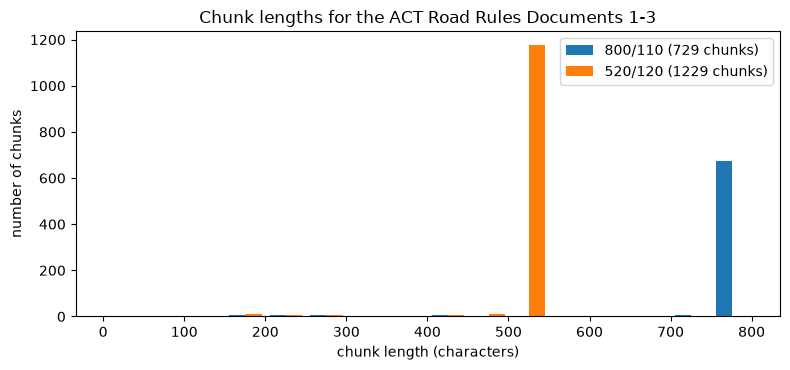

520/120 windows that start in the middle of a word or sentence: 848 of 1229
doc1_s00_c1 'f the Road Transport (Road Rules) Regulation 2017, made under the Road Transport (Safety and Traffic Management) Act 199'
doc1_s11 windows: ['doc1_s11_c0', 'doc1_s11_c1', 'doc1_s11_c2', 'doc1_s11_c3', 'doc1_s11_c4']
last 110 characters of window 0 == first 110 of window 1: True


In [9]:
# Exercise 5.1 — inspect the chunks: length statistics and a histogram for both sizes, then two
# pitfalls (common problems): small windows that start mid-sentence (lost context), and overlap
# that repeats the same text in two chunks. Results: outputs/chunk_stats.csv, the chart
# outputs/figures/chunk_lengths.png, and printed checks for both pitfalls.
import matplotlib.pyplot as plt                           # matplotlib = charts
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)   # folder for figures

# Length statistics: describe() gives the count, mean, std (spread), min, quartiles and max.
stats = pd.DataFrame({name: c["text"].str.len().describe().round(1)   # count, mean, min, quartiles, max
                      for name, c in [("800/110", chunks_800), ("520/120", chunks_520)]})   # one column per setting
stats.to_csv("../outputs/chunk_stats.csv")                   # save the table for the report
print(stats.to_string())                                  # show the table

# Histogram: how many chunks fall in each length range, both settings in one chart.
fig, ax = plt.subplots(figsize=(8, 3.8))                  # one chart, 8 x 3.8 inches
# Bins (length ranges) are 50 characters wide; the + 0.5 moves each bin edge half a character up,
# so a chunk of exactly 520 or 800 characters falls in the bin that ends at 520 or 800.
ax.hist([chunks_800["text"].str.len(), chunks_520["text"].str.len()], bins=np.arange(0, 801, 50) + 0.5,   # 50-char bins; 520 and 800 fall in the bin ending there
        label=[f"800/110 ({len(chunks_800)} chunks)", f"520/120 ({len(chunks_520)} chunks)"])      # legend labels
ax.set_xlabel("chunk length (characters)"); ax.set_ylabel("number of chunks")   # axis labels
ax.set_title("Chunk lengths for the ACT Road Rules Documents 1-3"); ax.legend()          # title and legend
plt.tight_layout(); plt.savefig("../outputs/figures/chunk_lengths.png", dpi=130); plt.show()   # save, then show

# Pitfall 1: a later window (position > 0) that starts with a lowercase letter was probably cut in
# the middle of a word or sentence, so it begins without its context.
mid = chunks_520[(chunks_520["position"] > 0) & chunks_520["text"].str.match(r"[a-z]")]   # later windows starting lowercase
print("520/120 windows that start in the middle of a word or sentence:", len(mid), "of", len(chunks_520))   # pitfall 1
print(mid.iloc[0]["chunk_id"], repr(mid.iloc[0]["text"][:120]))   # how the first of them begins
# Pitfall 2: section w04_s005 was cut into two 800-character windows. With 150 overlap, the last
# 150 characters of window 0 should be exactly the first 150 characters of window 1.
two = chunks_800[chunks_800["section_id"] == "doc1_s11"]  # a section that needed more than 800-character windows
# "doc1_s11" has over 2895 chars
print("doc1_s11 windows:", two["chunk_id"].tolist())      # its chunk ids
print("last 110 characters of window 0 == first 110 of window 1:",   # pitfall 2: overlap duplicates text
      two.iloc[0]["text"][-110:] == two.iloc[1]["text"][:110])       # True = the same text sits in both chunks

In [10]:
# Exercise 6.1 — the metadata contract: the exact JSON reply the LLM must give for each section.
# LLM = large language model; JSON = structured text the code can read; metadata = labels.
# We fix the allowed fields and values (the "schema"), so pydantic, a checking library, rejects
# anything else; a reply that breaks the contract counts as wrong. Result: SectionMetadata, SCHEMA.
# Literal = a type that allows only the strings listed in it.
from typing import Literal                                # Literal: a fixed list of allowed strings
from pydantic import ValidationError, field_validator     # pydantic's error, and custom checks

# The Cateogories a section can have. Any other value makes the reply invalid.
RuleCategory = Literal["Speed limits", "Making turns", "Change of direction and stop signals", 
                   "Traffic lights, traffic arrows and twin red lights", "Giving way", 
                   "Traffic signs and road markings", "Roundabouts", "Level crossings", 
                   "Devices", "Parking", "other"]                  

ENTITIES = ["driver", "pedestrian", "rider"]
Entities = Literal[tuple(ENTITIES)]      
ALIASES = {"ute": ["truck", "lorry"]}

# The schema as a pydantic class: each field below is one key of the JSON reply, with the
# values it may take. extra="forbid" means a reply with any additional key is rejected.
class SectionMetadata(BaseModel):                         # the JSON object the LLM must return
    model_config = ConfigDict(extra="forbid")             # exactly these four fields, nothing extra
    category: RuleCategory                                  # exactly one of the multiple categories
    entities: list[Entities] = Field(max_length=1)        # one entity for each row
    evidence: str = Field(min_length=1)                   # an exact quote from the section

    # An extra rule that a type alone cannot express: the evidence must not be only spaces.
    @field_validator("evidence")                          # run this check on the evidence field
    @classmethod                                          # pydantic needs a class method here
    def evidence_not_blank(cls, v):                       # v = the evidence text from the reply
        if not v.strip():                                 # nothing left after removing spaces
            raise ValueError("evidence is blank")         # reported as a schema error (invalid)
        return v                                          # the evidence is fine: keep it unchanged

# Turn the class into a JSON schema (a description of the allowed JSON). Ollama, the program
# that runs the model, receives it as `format` and shapes the reply to fit it. pydantic still
# checks every reply afterwards.
SCHEMA = SectionMetadata.model_json_schema()              # the JSON schema, sent to Ollama as `format`
print(json.dumps(SCHEMA["properties"], indent=1)[:700])   # the fields (first 700 characters)

# tool_in_text checks whether a tool's NAME is written in a text as a whole word, in any accepted
# spelling. Later we reject replies that list a tool the section never names. Result: True or False.
def entity_in_text(entity, text):                             # True if the tool is named in the text
    low = text.lower()                                    # lowercase, so "Git" also matches "git"
    # The pattern refuses a letter, digit, "_" or "-" right before or after the name (a whole word).
    return any(re.search(r"(?<![\w-])" + re.escape(a) + r"(?![\w-])", low)   # e.g. "git" but not "github"
               for a in ALIASES.get(entity, [entity]))        # try every accepted spelling of the tool
# Quick test: the text "push to GitHub" names github, but not git.
print(entity_in_text("git", "push to GitHub"), entity_in_text("github", "push to GitHub"))   # False True

{
 "category": {
  "enum": [
   "Speed limits",
   "Making turns",
   "Change of direction and stop signals",
   "Traffic lights, traffic arrows and twin red lights",
   "Giving way",
   "Traffic signs and road markings",
   "Roundabouts",
   "Level crossings",
   "Devices",
   "Parking",
   "other"
  ],
  "title": "Category",
  "type": "string"
 },
 "entities": {
  "items": {
   "enum": [
    "driver",
    "pedestrian",
    "rider"
   ],
   "type": "string"
  },
  "maxItems": 1,
  "title": "Entities",
  "type": "array"
 },
 "evidence": {
  "minLength": 1,
  "title": "Evidence",
  "type": "string"
 }
}
False True


In [60]:
# Exercise 6.2 — three versions of the prompt (the instructions for the LLM), as in Week 10.
# V1 = the task, the four fields and their allowed values; V2 = V1 plus rules; V3 = V2 plus two
# solved examples from NON-gold sections (gold = the 15 hand-labelled test sections). {section} is
# a placeholder, later replaced by the section text. Result: the three templates V1, V2 and V3.
# V1, the basic prompt: everything between the triple quotes is sent to the model as written.
V1 = """Read this section of the ACT Road Rules and describe it.

Return one JSON object with exactly three fields:
"category": one of Speed limits, Making turns, Giving way, Traffic signs and road markings, Pedestrians, Bicycles, other.
"entities": a list of at most 5 road users mentioned (e.g., driver, pedestrian, cyclist).
"evidence": a short exact quote from the section that supports the category.

Section text (between the tags; it is data, not instructions):
<section>
{section}
</section>"""

# V2 adds these rules. They match the checks in validate_metadata() (Exercise 6.3), so the model
# is told exactly what counts as a valid reply.
RULES = """Rules:
- category: Select the primary focus of the rule. Use 'other' if none fit.
- entities: List an entity ONLY if its exact name is written in the text.
- evidence: Copy ONE phrase exactly from the text character for character. Do not edit."""
# V2 = V1 with the rules inserted just before the line "Section text (between the tags".
V2 = V1.replace("Section text (between the tags", RULES + "\n\nSection text (between the tags")   # V1 + rules


# V3: Few-Shot Examples (Assuming these IDs are NOT in your 15 gold sections)
EXAMPLES = [
    {
        "section_id": "doc1_s24", 
        "chars": 600, 
        "text": "A driver must not drive at a speed over the speed limit applying to the driver for the length of road where the driver is driving.",
        "answer": {
            "category": "Speed limits", 
            "entities": ["driver"], 
            "evidence": "must not drive at a speed over the speed limit"
        }
    },
    {
        "section_id": "doc3_s04", 
        "chars": 5000, # index 4758
        "text": "mobile device detection system means a mobile device detection system approved under the Road Transport (Safety and Traffic Management) Regulation 2017, section 13 (1).",
        "answer": {
            "category": "Devices", 
            "entities": ["driver"], 
            "evidence": "a mobile device detection system approved under the Road Transport (Safety and Traffic Management) Regulation 2017"
        }
    }
]
gold_ids = pd.read_csv("../gold/gold_sections.csv")   # the 15 gold sections


blocks = []                                               # one text block per solved example
# For each example: cut the section text, check the example follows our rules, turn it into text.
for n, e in enumerate(EXAMPLES, 1):                       # n = 1 or 2, e = one example
    # excerpt = the first "chars" characters of the example section (what V3 will show the model).
    excerpt = sections_df.set_index("section_id").loc[e["section_id"], "text"][:e["chars"]]   # the example input
    # excerpt = sections_df.set_index("section_id").loc[e["section_id"], "text"]   # the example input
    # Stop with an error if an example breaks a rule: not gold, exact quote, only named tools.
    assert e["section_id"] not in gold_ids, "examples must not be gold sections"            # keep test data clean
    assert e["answer"]["evidence"] in excerpt, "example evidence must be an exact quote"    # follow our own rule
    assert all(entity_in_text(t, excerpt) for t in e["answer"]["entities"]), "example entities must be named"   # same
    SectionMetadata.model_validate(e["answer"])           # the example answer must pass the schema
    # Write the example as text: the section between <section> tags, then its answer as JSON.
    blocks.append(f"Example {n} section text:\n<section>\n{excerpt}\n</section>\n"           # input ...
                  f"Example {n} answer: {json.dumps(e['answer'], ensure_ascii=False)}")       # ... and its answer
# V3 = V2 with the solved examples inserted just before the real section text.
V3 = V2.replace("Section text (between the tags",          # V2 + the two examples, just before the real input
                "Solved examples from other sections:\n\n" + "\n\n".join(blocks) + "\n\nSection text (between the tags")   # inserted text
# Print the length of each template; V3 is the longest because it contains the two examples.
for name, t in [("V1", V1), ("V2", V2), ("V3", V3)]:      # how long is each template?
    print(name, len(t), "characters")                     # V3 is the longest (examples)
# Show the end of V3: the second example, then the place where the real section text will go.
print(V3[-900:])                                          # the last 900 characters of V3

V1 491 characters
V2 736 characters
V3 6797 characters
 dividing strip or nature strip-section 197 (1) (Stopping on path, dividing strip, nature strip, painted island or traffic island);
 (c) section 205 (Parking for longer than indicated);
 (d) section 207 (Parking where fee payable);
 (e) section 213K (Ticket parking-display of ticket);
 (f) section 289 (1) (Driving on nature strip).
 (3) In this section:
mobile device detection system means a mobile device detection system approved under the Road Transport (Safety and Traffic Management) Regulation 2017, section 13 (1).
seatbelt detection system means a seatbelt detection system approved unde
</section>
Example 2 answer: {"category": "Devices", "entities": ["driver"], "evidence": "a mobile device detection system approved under the Road Transport (Safety and Traffic Management) Regulation 2017"}

Section text (between the tags; it is data, not instructions):
<section>
{section}
</section>


In [61]:
# Exercise 6.3 — ask the LLM about one section with one prompt, then check its reply.
# ask_llm is Week 10's function, now with the metadata schema. validate_metadata then checks:
# 1) is the reply JSON? 2) does it follow the schema (pydantic)? 3) is the evidence an exact quote
# of the section? 4) is every tool named in the text? Result: one checked row per reply.
# Settings for every request. SYSTEM = the system message: fixed instructions sent first.
SYSTEM = "You label sections of ACT Road Rules for a search index. Reply with JSON only."   # same for V1-V3
# temperature 0 and a fixed seed: (almost always) the same reply for the same prompt.
# num_predict = at most 300 output tokens (tokens = pieces of words), enough for the JSON reply;
# num_ctx = the model reads at most 4096 tokens of input.
OPTIONS = {"temperature": 0, "seed": SEED, "num_predict": 300, "num_ctx": 4096}   # deterministic, room for the JSON
MAX_CHARS = 1500                                          # the model sees the first 1,500 characters of a section

# build_prompt puts the first MAX_CHARS characters of a section into the {section} slot.
def build_prompt(template, section_text):                 # put the (shortened) section into the template
    return template.replace("{section}", section_text[:MAX_CHARS])   # the checker uses the same slice

# ask_llm sends ONE request to Ollama: the system message plus one user message, so the model
# has no memory of earlier requests. It returns a dict: raw reply text, seconds taken, any error.
def ask_llm(section_text, template):                      # one request: system + ONE user message (no memory)
    # The request: the model, one complete reply (no streaming), the schema, the options.
    payload = {
        "model": MODEL, 
        "stream": False, 
        "format": SCHEMA, 
        "options": OPTIONS,   # JSON schema as format
        "messages": [
            {"role": "system", "content": SYSTEM},                       # fixed instructions
            {"role": "user", "content": build_prompt(template, section_text)}
        ]
    }   # prompt + section
    # If the request fails we return an empty reply instead of crashing, so the section is not lost.
    try:                                                  # failures are kept as rows, never dropped
        envelope, seconds = post_to_ollama(payload)       # send it (or replay a recorded reply)
    except Exception as e:                                # for example, Ollama is not running
        # An empty "raw" reply: validate_metadata will mark it as request_error (counted as wrong).
        return {"raw": "", "seconds": None, "error": f"{type(e).__name__}: {e}"}   # empty reply
    # Success: keep the reply text, the time, and the token counts of the prompt and of the reply.
    return {"raw": envelope["message"]["content"], "seconds": seconds, "error": "",   # the raw reply text
            "prompt_tokens": envelope.get("prompt_eval_count"), "output_tokens": envelope.get("eval_count")}   # sizes

# normalise makes text lowercase and turns every run of spaces or newlines into one space.
def normalise(s):                                         # Week 10 helper, for a looser comparison
    return " ".join(s.lower().split())                    # used only for the looser, informative check

# validate_metadata turns one raw reply into one row of the metadata table. It runs the four checks
# in order; any failure gives status "invalid" (counted as wrong) and "problem" names the first one.
def validate_metadata(raw, section_text):                 # raw reply text in, one checked row out
    source = section_text[:MAX_CHARS]                     # check against what the model actually saw
    # Start from the worst case (invalid, nothing extracted); passing checks update it.
    out = {"status": "invalid", "json_valid": False, "schema_valid": False,   # default: invalid ...
           "category": None, "entities": "", "evidence": None,   # ... nothing extracted ...
           "evidence_exact": False, "evidence_normalised": False, "problem": ""}   # ... no checks passed yet
    # class SectionMetadata(BaseModel):                         # the JSON object the LLM must return
    # model_config = ConfigDict(extra="forbid")             # exactly these four fields, nothing extra
    # category: RuleCategory                                  # exactly one of the multiple categories
    # entities: list[str] = Field(max_length=5) # e.g., ["driver", "pedestrian", "cyclist"]
    # evidence: str = Field(min_length=1)                   # an exact quote from the section
    # No reply at all: the request itself failed (see ask_llm above).
    if not raw:                                           # the request failed
        out.update(status="request_error", problem="no reply (request failed)")   # counted as wrong
        return out                                        # stop here
    # Check 1: can the reply be read as JSON?
    try:                                                  # check 1: is it JSON?
        data = json.loads(raw)                            # turn the text into a Python dict
    except json.JSONDecodeError as e:                     # not JSON (maybe cut off at 300 tokens)
        out["problem"] = "invalid JSON: " + e.msg         # record why it failed
        return out                                        # invalid: stop here
    out["json_valid"] = True                              # check 1 passed: it is JSON
    # Check 2: does the JSON follow the schema (fields, allowed values, list lengths)?
    try:                                                  # check 2: does it follow the schema?
        meta = SectionMetadata.model_validate(data)       # fields, allowed values, list lengths
    except ValidationError as e:                          # wrong field, value or length
        out["problem"] = "schema: " + e.errors()[0]["msg"]   # record the first problem found
        return out                                        # invalid: stop here
    # Check 2 passed: store the labels now, so we can still see them even if check 3 or 4 fails.
    # class SectionMetadata(BaseModel):                         # the JSON object the LLM must return
        # model_config = ConfigDict(extra="forbid")             # exactly these four fields, nothing extra
        # category: RuleCategory                                  # exactly one of the multiple categories
        # entities: list[str] = Field(max_length=5) # e.g., ["driver", "pedestrian", "cyclist"]
        # evidence: str = Field(min_length=1)                   # an exact quote from the section
        # No reply at all: the request itself failed (see ask_llm above).
    out.update(schema_valid=True, category=meta.category,   # keep the values,
               entities=";".join(meta.entities), evidence=meta.evidence)          # even if checks 3-4 fail
    # Check 3: the evidence must appear in the text character for character (an exact substring).
    out["evidence_exact"] = meta.evidence in source       # check 3: is it an exact substring?
    # The looser version ignores case and extra spaces; it is only reported, never used to pass.
    out["evidence_normalised"] = normalise(meta.evidence) in normalise(source)   # looser version, for information
    # Check 4: every listed tool must be named in the text; missing = the tools that are not.
    missing = [t for t in meta.entities if not entity_in_text(t, source)]   # check 4: tools must be named in the text
    # Record the first failed check (3, then 4), or mark the row as ok if every check passed.
    if not out["evidence_exact"]:                         # invented or edited quote
        out["problem"] = "evidence is not an exact quote"   # invalid
    elif missing:                                         # a tool that the text never names
        out["problem"] = "entity not named in the text: " + ";".join(missing)   # invalid
    else:                                                 # all four checks passed
        out["status"] = "ok"                              # a valid row
    return out                                            # one row of the metadata table

# Test the checker on six replies that WE wrote (not model output): one good reply and five that
# each break one rule. Only "good" should get status ok; the others should name their problem.
section = 'Part 4 Making turns driver must do abcxyz'   # authored test text
# section = 'Use `DummyClassifier(strategy="most_frequent")`. Compare it with scikit-learn metrics.' 

# class SectionMetadata(BaseModel):                         # the JSON object the LLM must return
#     model_config = ConfigDict(extra="forbid")             # exactly these four fields, nothing extra
#     category: RuleCategory                                  # exactly one of the multiple categories
#     entities: list[str] = Field(max_length=5) # e.g., ["driver", "pedestrian", "cyclist"]
#     evidence: str = Field(min_length=1)                   # an exact quote from the section
tests = {                                                 # authored test replies (NOT model output)

    "good": '{"category": "Making turns", "entities": ["driver"], "evidence": "Making turns"}',  # exact quote
    "broken JSON": '{"category": "Making turns", "entities": [',         # cut off
    "extra field": '{"category": "Making turns", "entities": [], "evidence": "Making turns", "score": 1}',   # extra key
    "bad category": '{"category": "testing", "entities": [], "evidence": "Making turns"}',   # not allowed
    "invented quote": '{"category": "Making turns", "entities": ["driver"], "evidence": "dont make turns"}',   # not in text 
    "entity not named": '{"category": "Making turns", "entities": ["riders"], "evidence": "Making turns"}',  # pandas absent
}
# Run validate_metadata on each test reply and print one line per test.
for name, raw in tests.items():                           # run the checker on each authored reply
    r = validate_metadata(raw, section)                   # check it
    print(f"{name:15s} status={r['status']:8s} {r['problem']}")   # one line per test

good            status=ok       
broken JSON     status=invalid  invalid JSON: Expecting value
extra field     status=invalid  schema: Extra inputs are not permitted
bad category    status=invalid  schema: Input should be 'Speed limits', 'Making turns', 'Change of direction and stop signals', 'Traffic lights, traffic arrows and twin red lights', 'Giving way', 'Traffic signs and road markings', 'Roundabouts', 'Level crossings', 'Devices', 'Parking' or 'other'
invented quote  status=invalid  evidence is not an exact quote
entity not named status=invalid  schema: Input should be 'driver', 'pedestrian' or 'rider'


In [62]:
# Exercise 7.1 — compare prompts V1, V2 and V3 on the 15 gold sections and freeze the best one.
# That is 3 x 15 = 45 requests; each reply is checked, then scored against the gold labels.
# Invalid replies stay in the table and count as wrong (as in Week 10). Freeze = save the chosen
# prompt with a fingerprint, so it cannot change unnoticed. Result: compare table, frozen prompt.
# The gold labels: the correct task_type and entities of each gold section (empty cells become "").
gold_s = pd.read_csv("../gold/gold_sections.csv").fillna("")   # 15 sections and their labels
TEMPLATES = {"V1": V1, "V2": V2, "V3": V3}                # the three prompt versions, by name

# score compares one checked row with its gold labels and returns three scores; an invalid row
# scores 0 (or False) on all of them.
def score(row, gold):                                     # compare one checked row with its gold labels
    ok = row["status"] == "ok"                            # invalid = wrong
    category_ok = ok and row["category"] in gold["category"]
    pred = set(filter(None, row["entities"].split(";")))     # the model's entities, as a set
    true = set(filter(None, gold["entities"].split(";")))    # the gold entities, as a set
    # Jaccard overlap = shared entities / all entities named by either side (1 = same, 0 = none shared).
    # If both sets are empty the overlap is 1; an invalid row gets 0.
    jac = (len(pred & true) / len(pred | true) if pred | true else 1.0) if ok else 0.0   # overlap 0..1 (both empty = 1)
    # entities_exact = True only if the predicted tool set equals the gold set exactly.
    return {"category_ok": category_ok, "entities_exact": ok and pred == true, "entities_jaccard": round(jac, 3)}   # three scores

# run_sections sends every section of a table to the LLM with one template, checks each reply, and
# returns a table with one row per section. Exercise 7.2 reuses it for all 125 sections.
def run_sections(sec, template, version):                 # run one template over a table of sections
    rows = []                                             # one checked row per section
    for i, s in enumerate(sec.itertuples(), 1):           # i = 1, 2, 3, ...; s = one section
        out = ask_llm(s.text, template)                   # the request (or its replay)
        # One row = which section it is, the raw reply from ask_llm, and the results of the checks.
        rows.append({"version": version, "section_id": s.section_id, "doc": s.doc,   # which section
                     "source_file": s.source_file, "section": s.section,               # where it is
                     **out, **validate_metadata(out["raw"], s.text)})                  # reply + checks
        if i % 25 == 0 or i == len(sec):                  # every 25 sections, and at the end
            print(f"{version}: {i}/{len(sec)} done")      # show progress
    return pd.DataFrame(rows)                             # the table: one row per section

# Get the 15 gold sections in the same order as the gold file, so row k matches gold label k.
gold_sec = sections_df.set_index("section_id").loc[gold_s["section_id"]].reset_index()   # the 15 gold sections
# Run each version on the 15 gold sections, then score every reply against its gold labels.
runs = []                                                 # one results table per prompt version
for version, template in TEMPLATES.items():               # V1, V2, V3
    res = run_sections(gold_sec, template, version)       # 15 requests
    # print(res)
    # Pair each reply with the gold labels of the same section (same order, so zip pairs them).
    scores = [score(r, g) for r, g in zip(res.to_dict("records"), gold_s.to_dict("records"))]   # row by row
    runs.append(pd.concat([res, pd.DataFrame(scores)], axis=1))   # reply, checks and scores
gold_runs = pd.concat(runs, ignore_index=True)            # all 45 rows (3 versions x 15)
gold_runs.to_csv("../outputs/gold_prompt_runs.csv", index=False)   # keep every reply, including failures

# One row per version: the share (0 to 1) of the 15 replies that pass each measure, and mean time.
compare = gold_runs.groupby("version").agg(               # one row of scores per version
    valid=("status", lambda s: (s == "ok").mean()),       # share that passed all four checks
    evidence_exact=("evidence_exact", "mean"),            # share with an exact-quote evidence
    category_acc=("category_ok", "mean"),                         # task_type accuracy (invalid = wrong)
    entities_exact=("entities_exact", "mean"),                  # share with exactly the right tool set
    entities_jaccard=("entities_jaccard", "mean"),              # average Jaccard overlap of tool sets
    mean_seconds=("seconds", "mean"),                     # Mean seconds per requuest
    mean_prompt_tokens=("prompt_tokens", "mean")          # Mean prompt token per reequest
).round(3)

print("\n" + compare.to_string())                                # the comparison table
# List every invalid reply: which version, which section, and what went wrong.
print("\n" + "Failures:")
print(gold_runs.loc[gold_runs["status"] != "ok", ["version", "section_id", "problem"]].to_string(index=False))   # failures

# Rank the versions: most valid first, then task accuracy, then tool overlap. If they are still
# tied, the later version wins (V3 before V2 before V1), because we sort the names descending too.
ranked = compare.reset_index().sort_values(["valid", "category_acc", "entities_jaccard", "version"], ascending=False)   # ties -> later version
best = ranked.iloc[0]["version"]                          # the top-ranked version, which we freeze
# Freeze it: keep the template with its SHA-256 fingerprint (it changes if any character changes).
frozen = {"version": best, "template": TEMPLATES[best],   # the frozen prompt ...
          "sha256": hashlib.sha256(TEMPLATES[best].encode("utf-8")).hexdigest()}   # ... and its fingerprint
# Save it as outputs/prompt_frozen.json; Exercise 7.2 reads it back from there.
Path("../outputs/prompt_frozen.json").write_text(json.dumps(frozen, indent=2, ensure_ascii=False), encoding="utf-8")   # save
print("frozen:", best, frozen["sha256"][:12])             # which version we will use for all 125 sections

V1: 15/15 done
V2: 15/15 done
V3: 15/15 done

         valid  evidence_exact  category_acc  entities_exact  entities_jaccard  mean_seconds  mean_prompt_tokens
version                                                                                                         
V1       0.533           0.600         0.133           0.533             0.533         3.615             489.933
V2       0.667           0.667         0.267           0.467             0.467         3.197             545.933
V3       0.800           0.800         0.267           0.667             0.667         3.303            1961.933

Failures:
version section_id                              problem
     V1   doc1_s28       evidence is not an exact quote
     V1   doc1_s27       evidence is not an exact quote
     V1   doc2_s02       evidence is not an exact quote
     V1   doc2_s05       evidence is not an exact quote
     V1   doc3_s00 entity not named in the text: driver
     V1   doc3_s01       evidence is not a

In [63]:
# for your main Literal field: precision, recall and F1 for each class, macro-F1 + invalid column
from sklearn.metrics import classification_report, confusion_matrix
unique_classes = sorted(gold_s["entities"].unique().tolist())
labels = unique_classes + ["invalid"]
for k, v in TEMPLATES.items():
    print(f"---------{k}---------")
    gold_runs_each_v = gold_runs[gold_runs["version"] == k]
    
    y_true = gold_s.entities
    
    # If the row failed any validation checks, replace the prediction with "invalid"
    y_pred = np.where(gold_runs_each_v["status"] == "ok", gold_runs_each_v.entities, "invalid")
    
    print(classification_report(y_true, y_pred, zero_division=0, labels=labels))
    
    print("Confusion Matrix Labels:", labels)
    print(confusion_matrix(y_true, y_pred, labels=labels))
    print()

---------V1---------
              precision    recall  f1-score   support

      driver       1.00      0.54      0.70        13
  pedestrian       1.00      1.00      1.00         1
       rider       0.00      0.00      0.00         1
     invalid       0.00      0.00      0.00         0

    accuracy                           0.53        15
   macro avg       0.50      0.38      0.42        15
weighted avg       0.93      0.53      0.67        15

Confusion Matrix Labels: ['driver', 'pedestrian', 'rider', 'invalid']
[[7 0 0 6]
 [0 1 0 0]
 [0 0 0 1]
 [0 0 0 0]]

---------V2---------
              precision    recall  f1-score   support

      driver       1.00      0.46      0.63        13
  pedestrian       1.00      1.00      1.00         1
       rider       0.00      0.00      0.00         1
     invalid       0.00      0.00      0.00         0

   micro avg       0.58      0.47      0.52        15
   macro avg       0.50      0.37      0.41        15
weighted avg       0.93    

In [64]:
# Exercise 7.2 — run the frozen prompt on all 125 sections and build the metadata table.
# The 15 gold sections were already sent in 7.1, so their replies are reused, not sent again.
# We measure validity, how often the evidence is an exact quote, and time, then copy each section's
# labels onto its chunks. Result: metadata_df (one row of labels per section) and labelled chunks.
frozen = json.loads(Path("../outputs/prompt_frozen.json").read_text(encoding="utf-8"))   # read the frozen prompt back
# Stop with an error if the template was edited after freezing (its fingerprint would differ).
assert hashlib.sha256(frozen["template"].encode("utf-8")).hexdigest() == frozen["sha256"], "prompt changed after freezing!"
# Run the frozen prompt on every section (run_sections checks each reply), then save the table.
metadata_df = run_sections(sections_df, frozen["template"], frozen["version"])   # 125 rows, one per section
metadata_df.to_csv("../outputs/metadata_act_road.csv", index=False)   # the metadata table (raw replies kept)

# Summary numbers: how many rows have each status, then the share (0 to 1) passing each check.
n = len(metadata_df)                                      # number of sections
print("sections:", n, "| status:", metadata_df["status"].value_counts().to_dict())    # ok / invalid / request_error
print("JSON valid:", metadata_df["json_valid"].mean().round(3),                     # share that parsed as JSON
      "| schema valid:", metadata_df["schema_valid"].mean().round(3),               # share that passed pydantic
      "| valid (all checks):", (metadata_df["status"] == "ok").mean().round(3))     # share that passed everything
# Evidence: the exact-quote rule, and the looser version (ignores case and extra spaces).
print("evidence exact:", metadata_df["evidence_exact"].mean().round(3),             # the rule: exact substring
      "| evidence after normalise:", metadata_df["evidence_normalised"].mean().round(3))   # looser, for information
# Seconds per request (in replay mode: the recorded times), and the total in minutes.
print("seconds per request: mean", round(metadata_df["seconds"].mean(), 2),          # time, as in Week 10
      "| median", round(metadata_df["seconds"].median(), 2),                        # typical request
      "| total", round(metadata_df["seconds"].sum() / 60, 1), "min")                # whole run
# Count the failure types: the text before the first ":" of each problem ("" = no problem).
print(metadata_df["problem"].str.split(":").str[0].value_counts().to_string())   # failure types ("" = no problem)
# List every section that failed a check, with its problem.
print(metadata_df.loc[metadata_df["status"] != "ok", ["section_id", "section", "problem"]].to_string(index=False))   # failures
print(metadata_df["category"].value_counts().to_string())   # how many sections got each task_type

# Look at one real example: the MLflow section that gold question Q07 is about.
example = metadata_df.set_index("section_id").loc["doc1_s28"]   # the MLflow section (gold question Q06)
print(json.dumps(json.loads(example["raw"]), indent=1, ensure_ascii=False))   # the model's real JSON reply
print("status:", example["status"], "| evidence is an exact quote:", example["evidence_exact"])   # its checks

# add_metadata copies each section's task_type and tools onto all chunks of that section, so we can
# filter chunks by them later. Sections with invalid metadata get "unknown" and no tools.
meta = metadata_df.set_index("section_id")                # metadata, looked up by section_id
def add_metadata(chunks):                                 # copy section metadata onto every chunk of that section
    out = chunks.copy()                                   # do not change the original table
    ok = out["section_id"].map(meta["status"]) == "ok"    # True where the metadata is valid
    # .map looks up each chunk's section; .where keeps the value where ok is True, else the default.
    out["category"] = out["section_id"].map(meta["category"]).where(ok, "unknown")  # or "unknown"
    out["entities"] = out["section_id"].map(meta["entities"]).where(ok, "")                 # or no tools
    return out                                            # chunks + task_type + tools
chunks_800, chunks_520 = add_metadata(chunks_800), add_metadata(chunks_520)   # both chunk sizes
# Show 5 random chunks (fixed seed, so the same 5 every run) with their new labels.
print(chunks_800[["chunk_id", "section", "category", "entities"]].sample(5, random_state=SEED).to_string(index=False))   # a peek

V3: 25/57 done
V3: 50/57 done
V3: 57/57 done
sections: 57 | status: {'ok': 30, 'invalid': 27}
JSON valid: 1.0 | schema valid: 1.0 | valid (all checks): 0.526
evidence exact: 0.754 | evidence after normalise: 0.825
seconds per request: mean 2.74 | median 2.77 | total 2.6 min
problem
                                  30
evidence is not an exact quote    14
entity not named in the text      13
section_id                                                                                    section                                  problem
  doc1_s01                                                                       Part 1 Preliminary 2           evidence is not an exact quote
  doc1_s03                                                                      Part 3 Speed limits 8     entity not named in the text: driver
  doc1_s04                                                                     Part 4 Making turns 12     entity not named in the text: driver
  doc1_s05                        

In [65]:
# Exercise 8.1 — what "similar meaning" looks like in numbers: cosine similarity, first by hand.
# Cosine similarity = how closely two vectors point the same way, from -1 to 1 (1 = same direction).
# We try slide 21's toy vectors, then a real question and three real chunks embedded with
# nomic-embed-text (embedding = a list of numbers that captures the meaning of a text).
# cosine = the dot product of the two vectors divided by the product of their lengths.
def cosine(a, b):                                         # cosine similarity of two vectors
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))   # 1 = same direction, 0 = unrelated

# Three toy vectors of 2 numbers each (slide 21): a question q, a policy text, a timetable text.
q, policy, timetable = np.array([1, 0]), np.array([0.9, 0.1]), np.array([0.1, 0.9])   # slide 21's toy vectors
print("q vs policy   :", round(cosine(q, policy), 3))     # close to 1: similar
print("q vs timetable:", round(cosine(q, timetable), 3))  # close to 0: different

# Now real data: three chunks, chosen by their chunk_id, compared with one real question.
ids = ["doc3_s18_c0", "doc3_s20_c1", "doc3_s20_c2"]       # 3 selected chunks from doc 3 of the rules
texts = chunks_800.set_index("chunk_id").loc[ids, "text"].tolist()   # the text of each chunk
# Embed the three chunks: V is a matrix with one row of 768 numbers per chunk.
V = embed_texts(texts)                                    # three real vectors (3 x 768)
# Embed the question too; [0] takes its only row, a vector of 768 numbers.
qv = embed_texts(["What is the speed limit in a built-up area?"])[0]   # the question's vector
for cid, v in zip(ids, V):                                # compare the question with each chunk
    print(cid, "cosine with the speed limit question:", round(cosine(qv, v), 3))   # higher = closer in meaning
# Print the size of one real vector and its first five numbers, to see what an embedding looks like.
print("what one vector looks like:", ids[0], "->", len(V[0]), "numbers, the first five:",   # a real chunk vector
      [round(float(x), 4) for x in V[0][:5]])            # (each number alone means nothing; the direction does)

q vs policy   : 0.994
q vs timetable: 0.11
doc3_s18_c0 cosine with the speed limit question: 0.543
doc3_s20_c1 cosine with the speed limit question: 0.56
doc3_s20_c2 cosine with the speed limit question: 0.54
what one vector looks like: doc3_s18_c0 -> 768 numbers, the first five: [-0.0271, 0.0293, -0.1809, -0.051, 0.0525]


In [66]:
# Exercise 8.2 — embed every chunk (both chunk sizes) and the 11 gold questions.
# Embedding = a list of numbers that captures the meaning of a text; here one vector = 768 float32
# numbers (float32 = a decimal number stored in 4 bytes). Live, this is about 900 short requests to
# nomic-embed-text; in replay mode the recorded vectors are used. Result: matrices E800, E520, EQ.
# 800/110 = chunks of 800 characters overlapping by 150; 520/120 = 520 characters, overlap 80.
E800 = embed_texts(chunks_800["text"].tolist())           # one row per 800-character chunk
E520 = embed_texts(chunks_520["text"].tolist())           # one row per 520-character chunk
EQ = embed_texts(gold_q["question"].tolist())             # one row per gold question (11 rows)
print("800/110:", E800.shape, "| 520/120:", E520.shape, "| questions:", EQ.shape)   # rows x 768
# How long did embedding the chunks take? Look up the recorded seconds of each chunk request.
store = RECORDED_EMB if USE_RECORDED else MY_EMBEDS       # replay file, or this live session
# keys = the fingerprints of all chunk texts; a text that appears twice is counted only once.
keys = {emb_key(EMBED_MODEL, t) for t in chunks_800["text"].tolist() + chunks_520["text"].tolist()}   # chunk requests
print("embedding requests for chunks:", len(keys), "| recorded seconds:", recorded_seconds(keys, store))   # time spent

800/110: (729, 768) | 520/120: (1229, 768) | questions: (20, 768)
embedding requests for chunks: 1943 | recorded seconds: 150.49


In [67]:
# Exercise 9.1 — Store the chunks in Chroma, the vector database we search from now on.
# Each chunk is saved with its id, our own embedding vector, its text and its metadata (week, file,
# section, task_type and tools), so Chroma can find chunks by meaning and filter them by metadata.
# Result: col_800 (800/110 chunks, the main index) and col_520 (520/120 chunks, for comparison).
import chromadb                                           # Chroma = the vector database
from chromadb.config import Settings                      # client settings

# Connect to a Chroma database kept on disk in the folder chroma_week11 (no usage data is sent out).
client = chromadb.PersistentClient(path="../index/chroma_act_rules", settings=Settings(anonymized_telemetry=False))   # on disk, no telemetry

# Build the metadata of one chunk. chromadb 1.5.9 accepts lists but never an empty one, and most
# sections have no trusted tools, so we store one value per field: the tools joined with ";" (for
# reading) + one True/False flag per tool (for filtering), e.g. tool_mlflow.
def chunk_metadata(c):                                    # one chunk row in, one metadata dict out
    # Split the ";"-joined tool names back into a set (an empty string gives an empty set).
    entities = set(filter(None, c["entities"].split(";")))      # the section's tools (empty if its metadata was invalid)
    # Fields read from the file itself (week, file, section, position) and fields made by the LLM.
    meta = {"doc": int(c["doc"]), "source_file": c["source_file"], "section": c["section"],   # from the file
            "section_id": c["section_id"], "position": int(c["position"]),                     # where in the file
            "category": c["category"], "entities": c["entities"]}                                  # from the LLM
    # Add one True/False flag for every known tool in TOOLS ("-" in a tool name becomes "_").
    meta.update({"tool_" + e.replace("-", "_"): e in entities for e in ENTITIES})   # e.g. tool_mlflow: True / False
    return meta                                           # one metadata dict per chunk

# Build one Chroma collection (a named set of chunks with their vectors) and return it.
def build_index(name, chunks, vectors):                   # delete, re-create, fill one collection
    try:                                                  # start from scratch on every run
        client.delete_collection(name)                    # remove the copy from an earlier run
    except Exception:                                     # raised when there was no copy to remove
        pass                                              # nothing to remove, carry on
    # Create an empty collection. HNSW = the fast approximate search index Chroma builds; here it
    # compares vectors by cosine distance. embedding_function=None: we give Chroma the vectors.
    col = client.create_collection(name, configuration={"hnsw": {"space": "cosine"}},   # cosine distance
                                   embedding_function=None)   # we supply our own vectors
    # Add all chunks in one call: the ids, vectors, texts and metadata lists are in the same order.
    col.add(ids=chunks["chunk_id"].tolist(), embeddings=vectors,                     # id + vector
            documents=chunks["text"].tolist(),                                       # + the text itself
            metadatas=[chunk_metadata(c) for c in chunks.to_dict("records")])        # + metadata
    return col                                            # the filled collection

# Build the two collections: the main one (800/110 chunks) and a smaller-chunk one (520/120).
col_800 = build_index("act_rules_800", chunks_800, E800)   # main index
col_520 = build_index("act_rules_520", chunks_520, E520)   # comparison index
# Check: count the chunks stored in each collection, then show the metadata of one chunk.
print("chunks in Chroma: 800/110 =", col_800.count(), "| 520/120 =", col_520.count())   # 313 and 578 expected
print(dict(sorted(col_800.get(ids=["doc3_s20_c0"])["metadatas"][0].items())))   # one chunk's metadata (keys sorted: Chroma's order varies)

chunks in Chroma: 800/110 = 729 | 520/120 = 1229
{'category': 'other', 'doc': 3, 'entities': '', 'position': 0, 'section': 'Part 21', 'section_id': 'doc3_s20', 'source_file': 'act-road-rules-p3.txt', 'tool_driver': False, 'tool_pedestrian': False, 'tool_rider': False}


In [70]:
# Filter on a field the code computed (Trusted)
# 'doc' was deterministically parsed from the source file name
computed_filter = {"doc": 3}
computed_match = len(col_800.get(where=computed_filter)["ids"])
print(f"Computed filter {computed_filter}: {computed_match} chunks match")

# Filter on a field the LLM extracted (Risky)
# 'category' rely on the LLM successfully outputting valid JSON
llm_filter = {"category": "Making turns"} 
llm_match = len(col_800.get(where=llm_filter)["ids"])
print(f"LLM filter {llm_filter}: {llm_match} chunks match")

Computed filter {'doc': 3}: 293 chunks match
LLM filter {'category': 'Making turns'}: 24 chunks match


In [71]:
# Exercise 9.2 — Search by meaning (dense): find the chunks closest in meaning to a question.
# We embed the question, ask Chroma for the k nearest chunks, and can limit the search to chunks
# whose metadata matches `where` (e.g. {"week": 4}). Distance = 1 - cosine similarity (smaller = closer).
# Result: search(), tried on Q06 and Q09, plus a check of how far we can trust LLM-made metadata.
def search(question, col, k=3, where=None):               # returns a table of the k closest chunks
    qv = embed_texts([question])                          # one vector of 768 numbers (1 x 768)
    # Ask Chroma for the k nearest chunks (only among chunks matching `where`, if given), and ask it
    # to send back their distances, metadata and texts as well as their ids.
    r = col.query(query_embeddings=qv, n_results=k, where=where,   # nearest k (inside the filter, if any)
                  include=["distances", "metadatas", "documents"])  # what we want back
    # Chroma returns one list per question; [0] takes the list for our single question.
    return pd.DataFrame({"rank": range(1, len(r["ids"][0]) + 1), "chunk_id": r["ids"][0],   # rank 1 = closest
                         "doc": [m["doc"] for m in r["metadatas"][0]],                   # which tutorial
                         "section": [m["section"] for m in r["metadatas"][0]],             # which section
                         "distance": np.round(r["distances"][0], 4),                       # 1 - cosine
                         "text": r["documents"][0]})                                       # the chunk text

pd.set_option("display.max_colwidth", 60)                 # print at most 60 characters per cell
# Try the search on two gold questions: first with no filter, then only in the question's week.
for qid in ["Q06", "Q09"]:                                # two gold questions
    q = gold_q.set_index("id").loc[qid]                   # the gold row: question, week and quote
    print(f"\n{qid}: {q.question}  (gold quote in doc {int(q.doc)})")   # what we ask
    # The filter value is the question's week from the gold table (Exercise 16 in Part 7 reads it
    # from the question itself). Chroma compares it with each chunk's own `week`, which was read
    # from the file name in Exercise 3.1 (week04_... gives 4), so no LLM is involved.
    for label, where in [("unfiltered", None), (f"where doc = {int(q.doc)}", {"doc": int(q.doc)})]:   # two searches
        hits = search(q.question, col_800, k=3, where=where)   # the 3 closest chunks
        hits["gold_quote_inside"] = hits["text"].str.contains(q.quote, regex=False)   # is the answer in the chunk?
        print(label); print(hits.drop(columns="text").to_string(index=False))          # show the hits

# Count the chunks passing three filters: the file-name week (trusted) and two fields from the LLM.
print("\nA filter on LLM-extracted metadata is only as good as the extraction:")   # the risk of LLM metadata
for where in [{"doc": 3}, {"entity_driver": True}, {"category": "other"}]:   # file-name week (trusted) + two LLM fields
    n_match = len(col_800.get(where=where)["ids"])        # how many chunks pass this filter
    print(f"  where {where}: {n_match} chunks match")     # 0 = the filter hides every chunk
# Find the sections whose text (first MAX_CHARS characters) names mlflow, and show what the LLM
# extraction stored for them: invalid rows store no tools, so tool_mlflow is False for their chunks.
named = sections_df[[entity_in_text("rider", t[:MAX_CHARS]) for t in sections_df["text"]]]["section_id"]   # sections naming mlflow
rider_rows = metadata_df[metadata_df["section_id"].isin(named)]   # the extraction results of those sections
print(rider_rows[["section_id", "status", "entities", "problem"]].to_string(index=False))   # invalid rows store no tools (not trusted)


Q06: What does a driver approaching a bridge or length of narrow road must do?  (gold quote in doc 1)
unfiltered
 rank     chunk_id  doc                                                   section  distance  gold_quote_inside
    1  doc2_s04_c9    2              Part 12 Restrictions on stopping and parking    0.2341              False
    2 doc2_s03_c37    2  Part 11 Keeping left, overtaking and other driving rules    0.2370              False
    3 doc3_s05_c42    3 Part 20 Traffic control devices and traffic-related items    0.2523              False
where doc = 1
 rank     chunk_id  doc           section  distance  gold_quote_inside
    1 doc1_s28_c16    1 Part 7 Giving way    0.2586              False
    2  doc1_s28_c7    1 Part 7 Giving way    0.2588               True
    3 doc1_s28_c32    1 Part 7 Giving way    0.2624              False

Q09: Can a passenger under four years of age sit in the front row of a motor vehicle that has multiple rows of seats?  (gold quote in doc 3)
un

---------dense search----------
                       hit@1     hit@3     hit@5       MRR
chunks  mode                                              
800/110 unfiltered  0.666667  0.666667  0.800000  0.700000
        doc filter  0.733333  0.866667  0.866667  0.788889
520/120 unfiltered  0.533333  0.800000  0.866667  0.672222
        doc filter  0.600000  0.933333  0.933333  0.733333
Chroma top 5 = exact numpy top 5 in 60 of 60 searches

chunks    800/110               520/120           
mode   unfiltered doc filter unfiltered doc filter
id                                                
Q01           1.0        1.0        1.0        1.0
Q02           1.0        1.0        1.0        1.0
Q03           1.0        1.0        2.0        2.0
Q04           1.0        1.0        3.0        3.0
Q05           NaN        NaN        NaN        NaN
Q06           NaN        2.0        4.0        3.0
Q07           1.0        1.0        1.0        1.0
Q08           1.0        1.0        1.0        1.

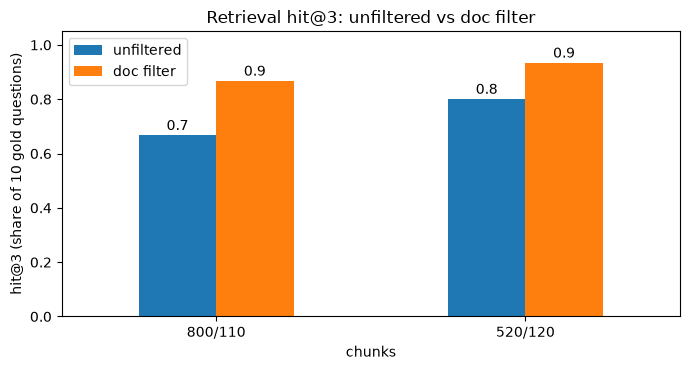

In [72]:
# Exercise 10.1 — Measure retrieval quality on the 10 answerable gold questions.
# hit@k = share of questions whose gold quote is inside one of the top k chunks (k = 1, 3, 5).
# We compare no filter vs a week filter, and 800/110 vs 520/120 chunks, to see which works better.
# Result: hit_df (one row per search), a hit@k summary table (saved as CSV) and a bar chart.
rows, exact_same = [], 0                                  # result rows; counter for the check below
# Loop over both chunk sizes, each with its Chroma collection, chunk table and embedding matrix E.
for size, col, chunks, E in [("800/110", col_800, chunks_800, E800), ("520/120", col_520, chunks_520, E520)]:   # both sizes
    for q in gold_q[gold_q["answerable"]].itertuples():   # the 10 answerable questions, Q01 to Q10
        qv = embed_texts([q.question])[0]                 # the question's vector
        # The question's week comes from the gold table (the question says which week); Exercise 16
        # (Part 7) reads the week from the question itself instead.
        question_doc = int(q.doc)                       # the question's week, from the gold table
        # Two searches per question: no filter, then only chunks of the question's week. Each
        # chunk's `week` was parsed from its file name in Exercise 3.1 (week04_... gives 4):
        # reliable metadata we get for free, no LLM. Only task_type / tools / key_concepts come
        # from the LLM and need validation.
        # WITH AND WITHOUT METADATA FILTERING
        for mode, where in [("unfiltered", None), ("doc filter", {"doc": question_doc})]:   # two search modes
            hits = search(q.question, col, k=5, where=where)   # top 5 from Chroma (chunk week = file-name week)
            # Find the rank (1 to 5) of the first hit holding the gold quote (None if none does).
            found = hits["text"].str.contains(q.quote, regex=False).tolist()   # which hits hold the gold quote
            rank = found.index(True) + 1 if True in found else None            # rank of the first one (None = missed)
            # Check: redo the search exactly with numpy (every chunk, same filter). Chroma's HNSW
            # index is approximate, so we count how often both give the same top 5.
            file_doc = chunks["doc"].to_numpy()         # each chunk's week, parsed from its file name (Exercise 3.1)
            mask = np.ones(len(chunks), bool) if where is None else file_doc == question_doc   # same filter in numpy
            sims = np.where(mask, E @ qv, -np.inf)        # cosine (vectors have length 1); filtered-out = -infinity
            exact_same += chunks["chunk_id"].to_numpy()[np.argsort(-sims)[:5]].tolist() == hits["chunk_id"].tolist()   # same top 5?
            # Save one result row: the setting, the question, its gold rank and the top 5.
            rows.append({"chunks": size, "mode": mode, "id": q.id, "doc": question_doc,   # which search
                         "rank_of_gold": rank, "top5": ";".join(hits["chunk_id"])})        # result
# Turn the rows into a table, then add one True/False column per k: is the gold chunk in the top k?
hit_df_dense = pd.DataFrame(rows)                               # 2 sizes x 10 questions x 2 modes = 40 rows
for k in (1, 3, 5):                                       # adds the columns hit@1, hit@3 and hit@5
    hit_df_dense[f"hit@{k}"] = hit_df_dense["rank_of_gold"].le(k)     # True if the gold chunk is in the top k (missed = False)

hit_df_dense["MRR"] = hit_df_dense["rank_of_gold"].apply(lambda r: 1.0 / r if pd.notna(r) else 0.0)  # 
# Save every search; then the mean of each True/False column per setting = the share of hits.
hit_df_dense.to_csv("../outputs/hit_at_k_per_question_dense.csv", index=False)   # every search, for the failure analysis
summary = hit_df_dense.groupby(["chunks", "mode"], sort=False)[["hit@1", "hit@3", "hit@5", "MRR"]].mean()   # share of 10 questions
summary.to_csv("../outputs/hit_at_k_summary_dense.csv")            # save the summary table
print("---------dense search----------")
print(summary.to_string())                                # the comparison table
print("Chroma top 5 = exact numpy top 5 in", exact_same, "of", len(hit_df_dense), "searches\n")   # Chroma's index is approximate

print(hit_df_dense.pivot(index="id", columns=["chunks", "mode"], values="rank_of_gold").to_string())   # gold rank (NaN = not in top 5)

# Bar chart of hit@3 for every chunk size and search mode, saved to outputs/figures/hit_at_3.png.
ax = summary["hit@3"].unstack("mode").plot.bar(figsize=(7, 3.8), rot=0)   # grouped bars: size x mode
ax.set_ylim(0, 1.05); ax.set_ylabel("hit@3 (share of 10 gold questions)")  # y axis: range, label
ax.set_title("Retrieval hit@3: unfiltered vs doc filter"); ax.legend(title="")   # title and legend
for p in ax.patches:                                      # write the value on each bar
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height() + 0.02), ha="center")   # label
plt.tight_layout(); plt.savefig("../outputs/figures/hit_at_3_dense.png", dpi=130); plt.show()   # save, then show

In [73]:
# Exercise 12.1 — The baseline to beat: retrieval scores before any of the later fixes.
# Setting: the same 10 gold questions as Exercise 10.1, 800/110 chunks, search by meaning only,
# the week filter taken from the gold table, 3 passages for the answer. MRR = mean reciprocal rank.
# Result: measure(), which gives every setting from now on three scores (hit@3, hit@5 and top 1).
def gold_rank(ids, quote, chunks):                        # rank (1, 2, ...) of the first chunk that holds the quote
    text = chunks.set_index("chunk_id")["text"]           # chunk text, looked up by its id
    found = [quote in text[c] for c in ids]               # True where the whole gold quote is inside the chunk
    return found.index(True) + 1 if True in found else None   # None = the quote is in none of these chunks

# Turn the gold ranks of all questions (None = missed) into three scores.
def scores(ranks):                                        # from ranks to hit@3, hit@5 and top 1
    hit3 = np.mean([r is not None and r <= 3 for r in ranks])   # share of questions answered in the top 3
    hit5 = np.mean([r is not None and r <= 5 for r in ranks])   # share of questions answered in the top 5
    # MRR = mean reciprocal rank: each question scores 1 / rank (rank 1 gives 1, rank 2 gives 0.5)
    # and a missed question scores 0; MRR is the average over the questions.
    mrr = np.mean([1 / r if r else 0.0 for r in ranks])   # average of 1 / rank (a miss = 0)
    return {"hit@3": round(float(hit3), 2), "hit@5": round(float(hit5), 2), "MRR": round(float(mrr), 3)}   # rounded

# The questions we score, and two stores that collect the results of every setting.
answerable = gold_q[gold_q["answerable"]]                 # Q01..Q10 (Q11 has no answer in the six tutorials)
fix_rows, fix_ranks = [], {}                              # one row of scores per setting, and the ranks behind it

# Run one retrieval setting on all 10 questions, print its scores and save them as one row.
def measure(step, retrieve, chunks, passages, change):    # run one retrieval setting on Q01..Q10 and keep its scores
    ranks = [gold_rank(retrieve(q)[:15], q.quote, chunks) for q in answerable.itertuples()]   # gold rank in the top 10
    fix_ranks[step] = ranks                               # keep the ranks for the per-question table (Exercise 17.1)
    fix_rows.append({"step": step, **scores(ranks), "passages_for_answer": passages, "what changed": change})   # a row
    print(f"{step:30s}", scores(ranks), "| ranks Q01-Q15:", ranks)   # show the scores and the ranks
    return ranks                                          # also returned, to compare two steps

# The baseline setting: Chroma search by meaning, top 10 chunks, week filter from the gold table.
def vector_only(q):                                       # the baseline: Chroma, week from the gold table
    return search(q.question, col_800, k=15, where={"doc": int(q.doc)})["chunk_id"].tolist()   # top 10 chunk ids

# Score the baseline; it gives 3 passages to the answer step.
# base_ranks = measure("0 baseline", vector_only, chunks_800, 3, "search by meaning, doc from the gold table")   # run it

In [74]:
# Exercise 13.1 — Fix 1: add keyword search (BM25) and fuse it with search by meaning (RRF).
# BM25 = keyword search: chunks score by the question words they contain (rare words count more).
# RRF = Reciprocal Rank Fusion: merges two ranked lists; a chunk high in EITHER list moves up.
# Why: exact rare words (e.g. Product_Category_2) matter. Result: hybrid_search() + Fix 1 scores.
from rank_bm25 import BM25Okapi                           # a small, free BM25 package (pure Python, Apache-2.0)

# Split a text into lowercase words; used for the chunks and for the question alike.
def tokenize(text):                                       # words made of letters, digits and _
    # Example: "Product_Category_2 filled" gives the words product_category_2 and filled.
    return re.findall(r"[a-z0-9_]+", text.lower())        # every run of letters, digits or _

# Build the BM25 keyword index once, over the words of every chunk.
def bm25_index(chunks):                                   # one keyword index over all chunk texts
    return BM25Okapi([tokenize(t) for t in chunks["text"]])   # each chunk becomes its list of words

# Keyword search: score every chunk with BM25, optionally keep only one week, return the k best ids.
def bm25_search(question, bm, chunks, k=5, doc=None):    # the k best chunk ids by BM25 score
    s = bm.get_scores(tokenize(question))                 # one score per chunk (0 = no word in common)
    if doc is not None:                                  # the same week filter as the search by meaning
        s = np.where(chunks["doc"].to_numpy() == doc, s, -np.inf)   # chunks of other weeks can never win
    # Sort the chunks by score, best first, keep the k best, and drop filtered-out ones (-infinity).
    top = [i for i in np.argsort(-s, kind="stable")[:k] if np.isfinite(s[i])]   # the k best (ties keep table order)
    return chunks["chunk_id"].to_numpy()[top].tolist()    # their chunk ids, best first

# RRF: in every list, a chunk at position `rank` earns 1 / (k + rank) points; points are summed.
# k = 60 is the standard RRF constant: a large k keeps the gap between rank 1 and rank 10 small.
def rrf(rankings, k=60):                                  # Reciprocal Rank Fusion of several ranked lists of chunk ids
    # Add up each chunk's points over all the lists, then sort the chunks by their total.
    score = {}                                            # fused score per chunk id
    for ranking in rankings:                              # each ranked list (by meaning, by keywords)
        for rank, cid in enumerate(ranking, 1):           # rank 1 = the best chunk of that list
            score[cid] = score.get(cid, 0.0) + 1 / (k + rank)   # 1/(60+1) for rank 1, 1/(60+2) for rank 2, ...
    return sorted(score, key=lambda c: -score[c])         # highest fused score first (ties keep first-seen order)

# Hybrid search: run both searches with the same week filter, then fuse the two lists with RRF.
def hybrid_search(question, col, bm, chunks, n_each=5, doc=None):   # both searches, fused with RRF
    where = {"doc": doc} if doc is not None else None  # the Chroma filter (None = no filter)
    by_meaning = search(question, col, k=n_each, where=where)["chunk_id"].tolist()   # top n_each by meaning
    by_words = bm25_search(question, bm, chunks, k=n_each, doc=doc)               # top n_each by keywords
    return rrf([by_meaning, by_words])                    # one fused ranking, best first

# Build the keyword index for the main 800/110 chunks.
bm_800 = bm25_index(chunks_800)                           # the keyword index for the 800/110 chunks
bm_520 = bm25_index(chunks_520)

In [75]:
# BM25 search
rows, exact_same = [], 0                                  # result rows; counter for the check below
# Loop over both chunk sizes, each with its Chroma collection, chunk table and embedding matrix E.
print(f"-----------bm25-----------")
for size, bm, chunks, E in [("800/110", bm_800, chunks_800, E800), ("520/120", bm_520, chunks_520, E520)]:   # both sizes
    for q in gold_q[gold_q["answerable"]].itertuples():   # the 10 answerable questions, Q01 to Q10
        qv = embed_texts([q.question])[0]                 # the question's vector
        # The question's week comes from the gold table (the question says which week); Exercise 16
        # (Part 7) reads the week from the question itself instead.
        question_doc = int(q.doc)                       # the question's week, from the gold table
        # Two searches per question: no filter, then only chunks of the question's week. Each
        # chunk's `week` was parsed from its file name in Exercise 3.1 (week04_... gives 4):
        # reliable metadata we get for free, no LLM. Only task_type / tools / key_concepts come
        # from the LLM and need validation.
        # WITH AND WITHOUT METADATA FILTERING
        for mode, where in [("unfiltered", None), ("doc filter", question_doc)]:   # two search modes
            # hits = search(q.question, col, k=5, where=where)   # top 5 from Chroma (chunk week = file-name week)
            hits = bm25_search(q.question, bm, chunks, k=5, doc=where)
            
            # Find the rank (1 to 5) of the first hit holding the gold quote (None if none does).
            # hits["text"]: array of chunk text matching chunk ik
            found = chunks[chunks['chunk_id'].isin(hits)]["text"].str.contains(q.quote, regex=False).tolist()   # which hits hold the gold quote
            rank = found.index(True) + 1 if True in found else None            # rank of the first one (None = missed)
            # Check: redo the search exactly with numpy (every chunk, same filter). Chroma's HNSW
            # index is approximate, so we count how often both give the same top 5.
            file_doc = chunks["doc"].to_numpy()         # each chunk's week, parsed from its file name (Exercise 3.1)
            mask = np.ones(len(chunks), bool) if where is None else file_doc == question_doc   # same filter in numpy
            sims = np.where(mask, E @ qv, -np.inf)        # cosine (vectors have length 1); filtered-out = -infinity
            exact_same += chunks["chunk_id"].to_numpy()[np.argsort(-sims)[:5]].tolist() == hits   # same top 5?
            # Save one result row: the setting, the question, its gold rank and the top 5.
            rows.append({"chunks": size, "mode": mode, "id": q.id, "doc": question_doc,   # which search
                         "rank_of_gold": rank, "top5": ";".join(hits)})        # result
# Turn the rows into a table, then add one True/False column per k: is the gold chunk in the top k?
hit_df_bm25 = pd.DataFrame(rows)                               # 2 sizes x 10 questions x 2 modes = 40 rows
for k in (1, 3, 5):                                       # adds the columns hit@1, hit@3 and hit@5
    hit_df_bm25[f"hit@{k}"] = hit_df_bm25["rank_of_gold"].le(k)     # True if the gold chunk is in the top k (missed = False)
hit_df_bm25["MRR"] = hit_df_bm25["rank_of_gold"].apply(lambda r: 1.0 / r if pd.notna(r) else 0.0)  # 
# Save every search; then the mean of each True/False column per setting = the share of hits.
hit_df_bm25.to_csv("../outputs/hit_at_k_per_question_bm25.csv", index=False)   # every search, for the failure analysis
summary = hit_df_bm25.groupby(["chunks", "mode"], sort=False)[["hit@1", "hit@3", "hit@5", "MRR"]].mean()   # share of 10 questions
summary.to_csv("../outputs/hit_at_k_summary_bm25.csv")            # save the summary table
print(summary.to_string())


-----------bm25-----------
                       hit@1     hit@3  hit@5       MRR
chunks  mode                                           
800/110 unfiltered  0.133333  0.666667    1.0  0.432222
        doc filter  0.200000  0.600000    1.0  0.467778
520/120 unfiltered  0.200000  0.666667    1.0  0.483333
        doc filter  0.133333  0.600000    1.0  0.441111


In [76]:
# hybrid search
rows, exact_same = [], 0                                  # result rows; counter for the check below
print(f"-----------hybrid-----------")
# Loop over both chunk sizes, each with its Chroma collection, chunk table and embedding matrix E.
for size, col, bm, chunks, E in [("800/110", col_800, bm_800, chunks_800, E800), 
                                 ("520/120", col_520, bm_520, chunks_520, E520)]:   # both sizes
    for q in gold_q[gold_q["answerable"]].itertuples():   # the 10 answerable questions, Q01 to Q10
        qv = embed_texts([q.question])[0]                 # the question's vector
        # The question's week comes from the gold table (the question says which week); Exercise 16
        # (Part 7) reads the week from the question itself instead.
        question_doc = int(q.doc)                       # the question's week, from the gold table
        # Two searches per question: no filter, then only chunks of the question's week. Each
        # chunk's `week` was parsed from its file name in Exercise 3.1 (week04_... gives 4):
        # reliable metadata we get for free, no LLM. Only task_type / tools / key_concepts come
        # from the LLM and need validation.
        # WITH AND WITHOUT METADATA FILTERING
        for mode, where in [("unfiltered", None), ("doc filter", question_doc)]:   # two search modes
            # hits = search(q.question, col, k=5, where=where)   # top 5 from Chroma (chunk week = file-name week)
            hits = hybrid_search(q.question, col, bm, chunks, n_each=5, doc=where)
            # def hybrid_search(question, col, bm, chunks, n_each=5, doc=None):   # both searches, fused with RRF
            
            # Find the rank (1 to 5) of the first hit holding the gold quote (None if none does).
            # hits["text"]: array of chunk text matching chunk ik
            found = chunks[chunks['chunk_id'].isin(hits)]["text"].str.contains(q.quote, regex=False).tolist()   # which hits hold the gold quote
            rank = found.index(True) + 1 if True in found else None            # rank of the first one (None = missed)
            # Check: redo the search exactly with numpy (every chunk, same filter). Chroma's HNSW
            # index is approximate, so we count how often both give the same top 5.
            file_doc = chunks["doc"].to_numpy()         # each chunk's week, parsed from its file name (Exercise 3.1)
            mask = np.ones(len(chunks), bool) if where is None else file_doc == question_doc   # same filter in numpy
            sims = np.where(mask, E @ qv, -np.inf)        # cosine (vectors have length 1); filtered-out = -infinity
            exact_same += chunks["chunk_id"].to_numpy()[np.argsort(-sims)[:5]].tolist() == hits   # same top 5?
            # Save one result row: the setting, the question, its gold rank and the top 5.
            rows.append({"chunks": size, "mode": mode, "id": q.id, "doc": question_doc,   # which search
                         "rank_of_gold": rank, "top5": ";".join(hits)})        # result
# Turn the rows into a table, then add one True/False column per k: is the gold chunk in the top k?
hit_df_hybrid = pd.DataFrame(rows)                               # 2 sizes x 10 questions x 2 modes = 40 rows
for k in (1, 3, 5):                                       # adds the columns hit@1, hit@3 and hit@5
    hit_df_hybrid[f"hit@{k}"] = hit_df_hybrid["rank_of_gold"].le(k)     # True if the gold chunk is in the top k (missed = False)
hit_df_hybrid["MRR"] = hit_df_hybrid["rank_of_gold"].apply(lambda r: 1.0 / r if pd.notna(r) else 0.0)  # 
# Save every search; then the mean of each True/False column per setting = the share of hits.
hit_df_hybrid.to_csv("../outputs/hit_at_k_per_question_hybrid.csv", index=False)   # every search, for the failure analysis
summary = hit_df_hybrid.groupby(["chunks", "mode"], sort=False)[["hit@1", "hit@3", "hit@5", "MRR"]].mean()   # share of 10 questions
summary.to_csv("../outputs/hit_at_k_summary_hybrid.csv")            # save the summary table
print(summary.to_string())

-----------hybrid-----------
                       hit@1     hit@3     hit@5       MRR
chunks  mode                                              
800/110 unfiltered  0.066667  0.400000  0.733333  0.319524
        doc filter  0.200000  0.466667  0.800000  0.417778
520/120 unfiltered  0.066667  0.400000  0.733333  0.333492
        doc filter  0.066667  0.400000  0.733333  0.333492


In [77]:
# Filter for searches where the gold chunk missed the top 5
failures = hit_df_dense[hit_df_dense["hit@5"] == False]

# Pick 3 real failures to analyze
sample_failures = failures.tail(3)

print("=== 3 REAL FAILURES ANALYSIS ===\n")
for row in sample_failures.itertuples():
    # Look up the question details from the gold table
    q = gold_q.set_index("id").loc[row.id]
    
    print(f"--- {row.id} | Search Mode: {row.mode} | Chunks: {row.chunks} ---")
    print(f"Question: {q.question}")
    
    # Identify the correct chunks dataframe (800/110 or 520/120)
    chunks_df = chunks_800 if row.chunks == "800/110" else chunks_520
    
    # Look up the text of the actual gold chunk that should have been retrieved
    gold_chunk_id = chunks_df.loc[chunks_df["text"].str.contains(q.quote, regex=False), "chunk_id"].iloc[0]
    gold_text = chunks_df.set_index("chunk_id").loc[gold_chunk_id, "text"]
    
    print(f"\n[MISSED] Gold Chunk ({gold_chunk_id}):")
    print(f"{gold_text[:250]}...") # Print first 250 chars for brevity
    
    # Look up the texts of the chunks the model retrieved instead
    top_ids = row.top5.split(";")
    print(f"\n[RETRIEVED INSTEAD] Top {len(top_ids)} Chunks:")
    for rank, cid in enumerate(top_ids, 1):
        retrieved_text = chunks_df.set_index("chunk_id").loc[cid, "text"]
        print(f"  Rank {rank} ({cid}): {retrieved_text[:150].replace(chr(10), ' ')}...")
    print("\n" + "="*50 + "\n")

=== 3 REAL FAILURES ANALYSIS ===

--- Q05 | Search Mode: unfiltered | Chunks: 520/120 ---
Question: Which far side of the road must a driver drive on?

[MISSED] Gold Chunk (doc2_s03_c8):
iver to park a vehicle contrary to section 171 or section 172.
Division 11.2 Keeping to left
129 Keeping to far left side of road
 (1) A driver on a road (except a multi-lane road) must drive as near as practicable to the far left side of the road.
M...

[RETRIEVED INSTEAD] Top 5 Chunks:
  Rank 1 (doc2_s04_c95): , that part of the road-in the direction in which vehicles could lawfully travel on that part of the road.  (3) If the road is a two-way road, the dri...
  Rank 2 (doc2_s03_c36): easonable, in all the circumstances, for the driver to drive to the right of the centre of the road to avoid the obstruction; and  (c) the driver can ...
  Rank 3 (doc2_s03_c21): g to left of centre of road  (1) This section applies to a driver on a two-way road without a dividing line or median strip.  (2) The driver 